<a href="https://colab.research.google.com/github/iamnoob96/Akshar_Sinha/blob/main/Phase_1_Exploratory_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cell 1: Import Libraries and Load Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/happiness.csv"
df = pd.read_csv(url)

print("Shape of dataset:", df.shape)
display(df.head())

Shape of dataset: (17137, 34)


,rownames,year,workstat,prestige,divorce,widowed,educ,reg16,babies,preteen,...,occattend,regattend,y94,y96,y98,y00,y02,y04,y06,unem10
0,1,1994,keeping house,46.0,NaN,iap,12.0,middle atlantic,2.0,3.0,...,1.0,0.0,1,0,0,0,0,0,0,1.0
1,2,1994,working fulltime,22.0,no,iap,12.0,foreign,0.0,0.0,...,0.0,0.0,1,0,0,0,0,0,0,0.0
2,3,1994,working fulltime,29.0,no,iap,12.0,foreign,0.0,0.0,...,0.0,1.0,1,0,0,0,0,0,0,NaN
3,4,1994,working fulltime,42.0,yes,iap,8.0,foreign,0.0,0.0,...,0.0,0.0,1,0,0,0,0,0,0,1.0
4,5,1994,working parttime,36.0,NaN,NaN,13.0,middle atlantic,0.0,1.0,...,0.0,0.0,1,0,0,0,0,0,0,0.0


# Cell 2: Basic Statistical Analysis

In [2]:
print("Dataset Info:")
df.info()

print("\nStatistical Summary (numeric + categorical):")
display(df.describe(include='all').T)

print("\nUnique values per column:")
display(df.nunique().sort_values(ascending=False))

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17137 entries, 0 to 17136
Data columns (total 34 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   rownames     17137 non-null  int64  
 1   year         17137 non-null  int64  
 2   workstat     17134 non-null  object 
 3   prestige     16283 non-null  float64
 4   divorce      9754 non-null   object 
 5   widowed      11096 non-null  object 
 6   educ         17093 non-null  float64
 7   reg16        17137 non-null  object 
 8   babies       17036 non-null  float64
 9   preteen      17036 non-null  float64
 10  teens        17049 non-null  float64
 11  income       15045 non-null  object 
 12  region       17137 non-null  object 
 13  attend       16864 non-null  object 
 14  happy        17137 non-null  object 
 15  owngun       11297 non-null  object 
 16  tvhours      11794 non-null  float64
 17  vhappy       17137 non-null  int64  
 18  mothfath16   17132 non-null  flo

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
rownames,17137.0,NaN,NaN,NaN,8569.0,4947.170117,1.0,4285.0,8569.0,12853.0,17137.0
year,17137.0,NaN,NaN,NaN,1999.47412,4.143358,1994.0,1996.0,1998.0,2004.0,2006.0
workstat,17134,8,working fulltime,9214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
prestige,16283.0,NaN,NaN,NaN,43.877541,13.873965,17.0,33.0,43.0,51.0,86.0
divorce,9754,2,no,7421,NaN,NaN,NaN,NaN,NaN,NaN,NaN
widowed,11096,2,iap,10718,NaN,NaN,NaN,NaN,NaN,NaN,NaN
educ,17093.0,NaN,NaN,NaN,13.319078,2.986785,0.0,12.0,13.0,16.0,20.0
reg16,17137,10,e. nor. central,3148,NaN,NaN,NaN,NaN,NaN,NaN,NaN
babies,17036.0,NaN,NaN,NaN,0.207091,0.540542,0.0,0.0,0.0,0.0,6.0
preteen,17036.0,NaN,NaN,NaN,0.255753,0.621533,0.0,0.0,0.0,0.0,6.0



Unique values per column:


,0
rownames,17137
prestige,59
tvhours,22
educ,21
income,12
reg16,10
region,9
attend,9
workstat,8
year,7


# Cell 3: Handling Missing Data

,Missing Count,Missing %
gwbush04,15207,88.737819
gwbush00,13701,79.949816
divorce,7383,43.082220
widowed,6041,35.251211
owngun,5840,34.078310
unem10,5796,33.821556
tvhours,5343,31.178153
income,2092,12.207504
prestige,854,4.983369
attend,273,1.593044


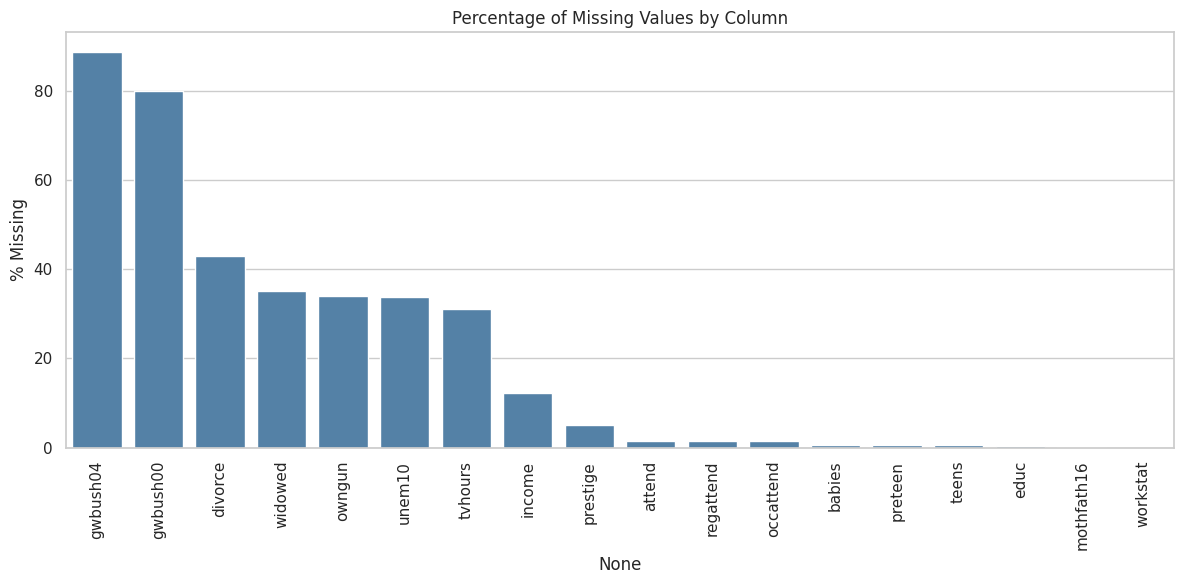

Dropped columns (>40% missing): ['gwbush04', 'gwbush00', 'divorce']

Remaining missing values after imputation: 0


/tmp/ipykernel_1970/463819707.py:27: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mode()[0], inplace=True)
/tmp/ipykernel_1970/463819707.py:25: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try u

In [3]:
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing %', ascending=False)
display(missing_df)

plt.figure(figsize=(12, 6))
sns.barplot(x=missing_df.index, y=missing_df['Missing %'], color='steelblue')
plt.xticks(rotation=90)
plt.title("Percentage of Missing Values by Column")
plt.ylabel("% Missing")
plt.tight_layout()
plt.show()

cols_to_drop = missing_df[missing_df['Missing %'] > 40].index.tolist()
df.drop(columns=cols_to_drop, inplace=True)
print("Dropped columns (>40% missing):", cols_to_drop)

for col in df.columns:
    if df[col].isnull().sum() > 0:
        if df[col].dtype in ['float64', 'int64']:
            df[col].fillna(df[col].median(), inplace=True)
        else:
            df[col].fillna(df[col].mode()[0], inplace=True)

print("\nRemaining missing values after imputation:", df.isnull().sum().sum())

# Cell 4: Data Cleaning

In [4]:
before = df.shape[0]
df.drop_duplicates(inplace=True)
print(f"Removed {before - df.shape[0]} duplicate rows")

cat_cols = df.select_dtypes(include='object').columns
for col in cat_cols:
    df[col] = df[col].astype(str).str.strip().str.lower()

df.replace('iap', np.nan, inplace=True)
for col in df.columns:
    if df[col].isnull().sum() > 0:
        if df[col].dtype in ['float64', 'int64']:
            df[col].fillna(df[col].median(), inplace=True)
        else:
            df[col].fillna(df[col].mode()[0], inplace=True)

print("Data cleaning complete. Shape:", df.shape)
display(df.head())

Removed 0 duplicate rows
Data cleaning complete. Shape: (17137, 31)


/tmp/ipykernel_1970/1496820215.py:18: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mode()[0], inplace=True)


,rownames,year,workstat,prestige,widowed,educ,reg16,babies,preteen,teens,...,occattend,regattend,y94,y96,y98,y00,y02,y04,y06,unem10
0,1,1994,keeping house,46.0,yes,12.0,middle atlantic,2.0,3.0,0.0,...,1.0,0.0,1,0,0,0,0,0,0,1.0
1,2,1994,working fulltime,22.0,yes,12.0,foreign,0.0,0.0,0.0,...,0.0,0.0,1,0,0,0,0,0,0,0.0
2,3,1994,working fulltime,29.0,yes,12.0,foreign,0.0,0.0,0.0,...,0.0,1.0,1,0,0,0,0,0,0,0.0
3,4,1994,working fulltime,42.0,yes,8.0,foreign,0.0,0.0,0.0,...,0.0,0.0,1,0,0,0,0,0,0,1.0
4,5,1994,working parttime,36.0,yes,13.0,middle atlantic,0.0,1.0,1.0,...,0.0,0.0,1,0,0,0,0,0,0,0.0


# Cell 5: Data Transformation

In [5]:
income_order = ['lt $1000', '$1000 to 2999', '$3000 to 3999', '$4000 to 4999', '$5000 to 5999', '$6000 to 6999', '$7000 to 7999', '$8000 to 9999', '$10000 - 14999', '$15000 - 19999', '$20000 - 24999', '$25000 or more']
income_map = {val: i for i, val in enumerate(income_order)}
df['income_ordinal'] = df['income'].map(income_map)
df['income_ordinal'].fillna(df['income_ordinal'].median(), inplace=True)

happy_order = ['not too happy', 'pretty happy', 'very happy']
df['happy'] = pd.Categorical(df['happy'], categories=happy_order, ordered=True)
df['happy_score'] = df['happy'].cat.codes

df['total_children'] = df['babies'] + df['preteen'] + df['teens']

print("New columns added: income_ordinal, happy_score, total_children")
display(df[['income', 'income_ordinal', 'happy', 'happy_score', 'total_children']].head())

New columns added: income_ordinal, happy_score, total_children


/tmp/ipykernel_1970/3575197137.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['income_ordinal'].fillna(df['income_ordinal'].median(), inplace=True)


,income,income_ordinal,happy,happy_score,total_children
0,$10000 - 14999,8,pretty happy,1,5.0
1,$25000 or more,11,very happy,2,0.0
2,$15000 - 19999,9,pretty happy,1,0.0
3,$15000 - 19999,9,not too happy,0,0.0
4,$10000 - 14999,8,not too happy,0,2.0


# Cell 6: Univariate Analysis

/tmp/ipykernel_1970/65000070.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='happy', data=df, order=happy_order, palette='viridis')


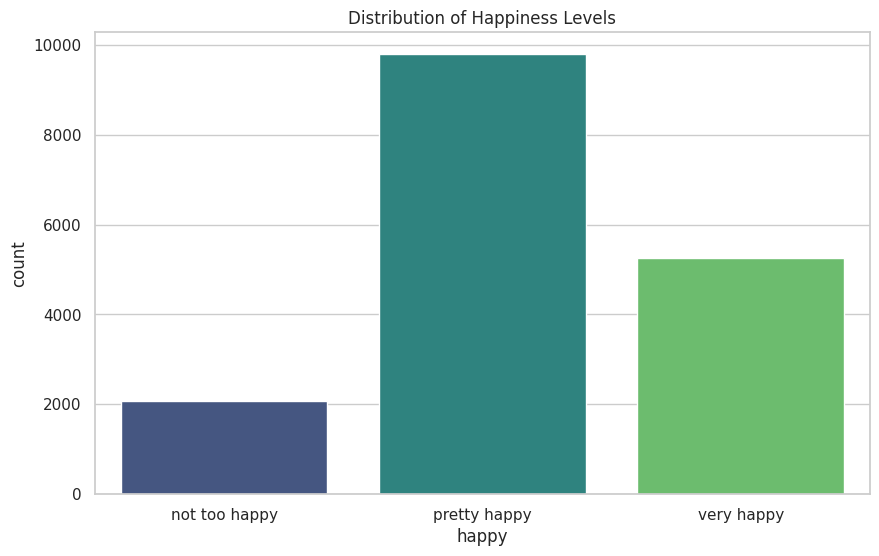

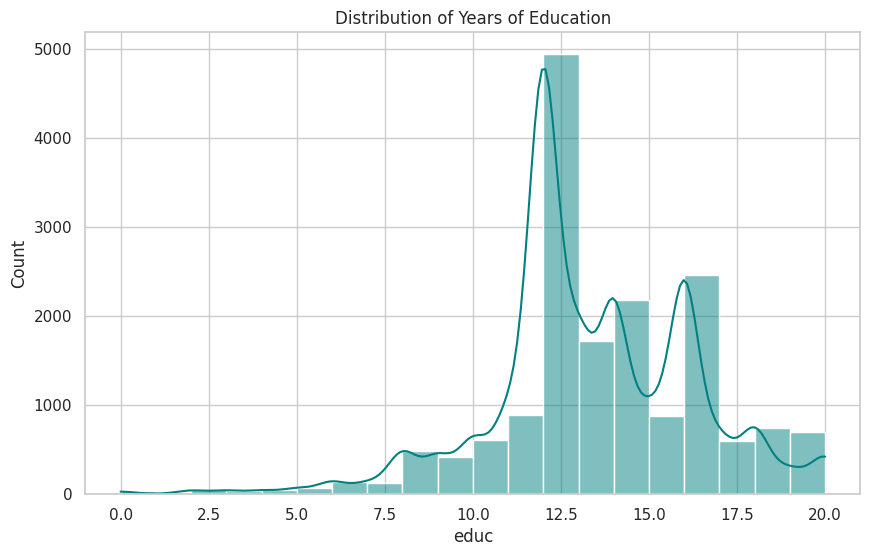

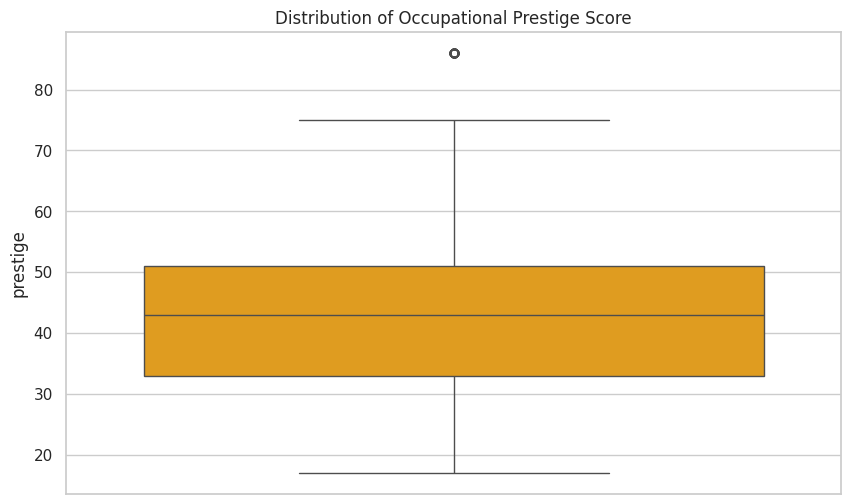

In [6]:
plt.figure()
sns.countplot(x='happy', data=df, order=happy_order, palette='viridis')
plt.title("Distribution of Happiness Levels")
plt.show()

plt.figure()
sns.histplot(df['educ'], bins=20, kde=True, color='teal')
plt.title("Distribution of Years of Education")
plt.show()

plt.figure()
sns.boxplot(y=df['prestige'], color='orange')
plt.title("Distribution of Occupational Prestige Score")
plt.show()

# Cell 7: Bivariate Analysis

/tmp/ipykernel_1970/3747229621.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='happy', y='income_ordinal', data=df, order=happy_order, palette='coolwarm')


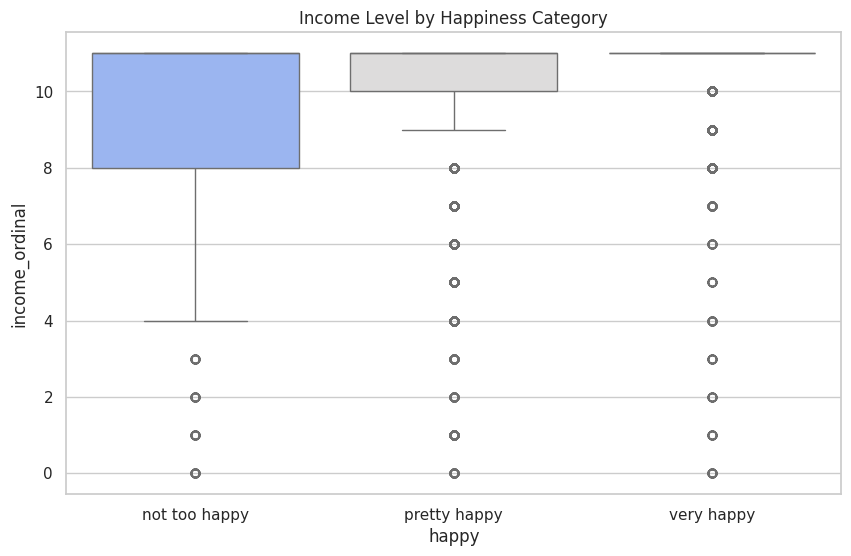

/tmp/ipykernel_1970/3747229621.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='happy', y='educ', data=df, order=happy_order, palette='mako')


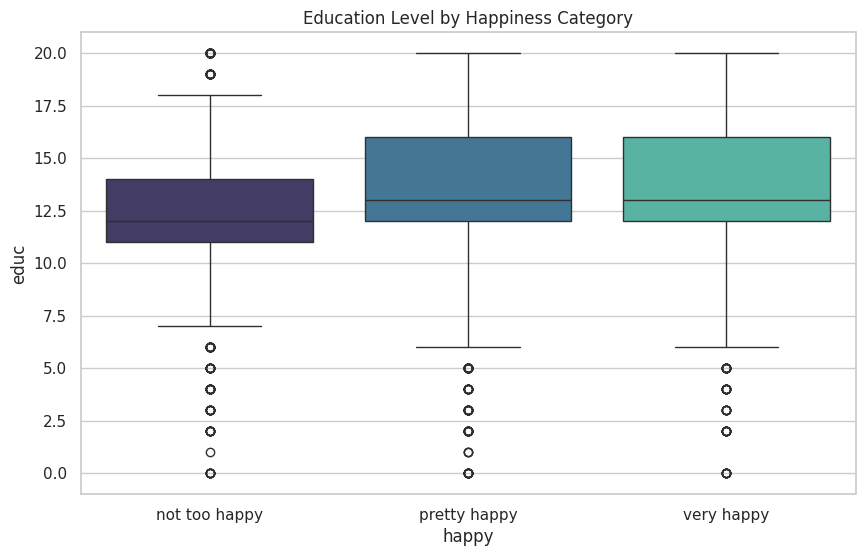

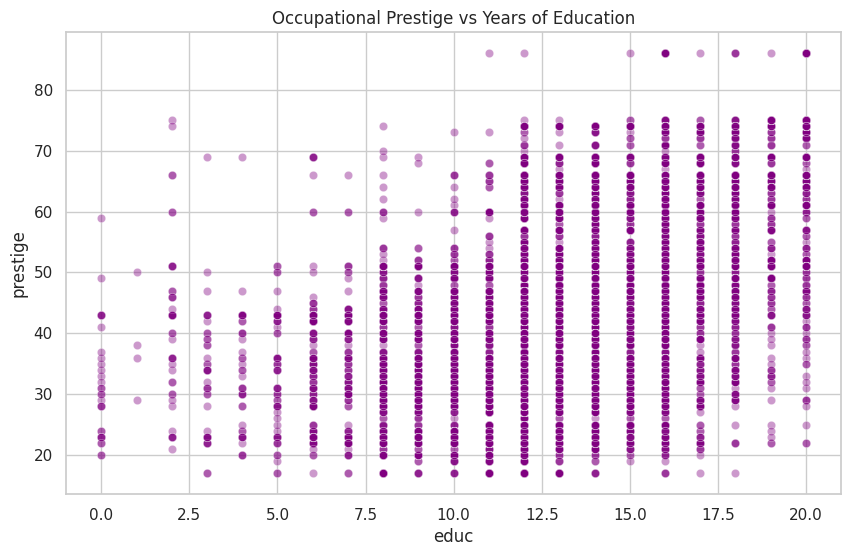

In [7]:
plt.figure()
sns.boxplot(x='happy', y='income_ordinal', data=df, order=happy_order, palette='coolwarm')
plt.title("Income Level by Happiness Category")
plt.show()

plt.figure()
sns.boxplot(x='happy', y='educ', data=df, order=happy_order, palette='mako')
plt.title("Education Level by Happiness Category")
plt.show()

plt.figure()
sns.scatterplot(x='educ', y='prestige', data=df, alpha=0.4, color='purple')
plt.title("Occupational Prestige vs Years of Education")
plt.show()

# Cell 8: Multivariate Analysis

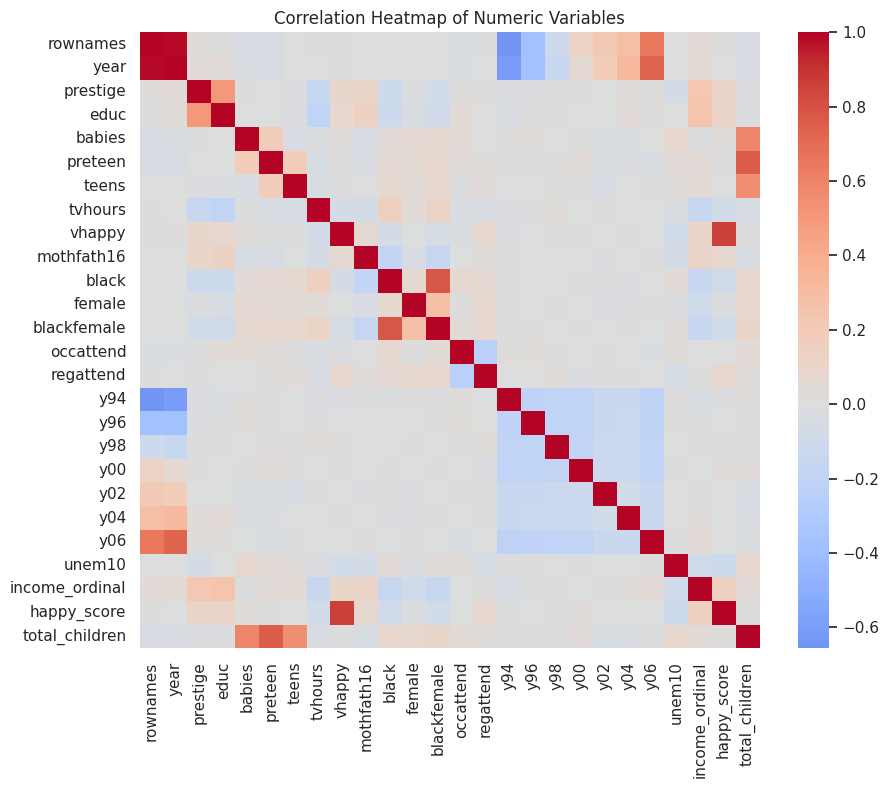

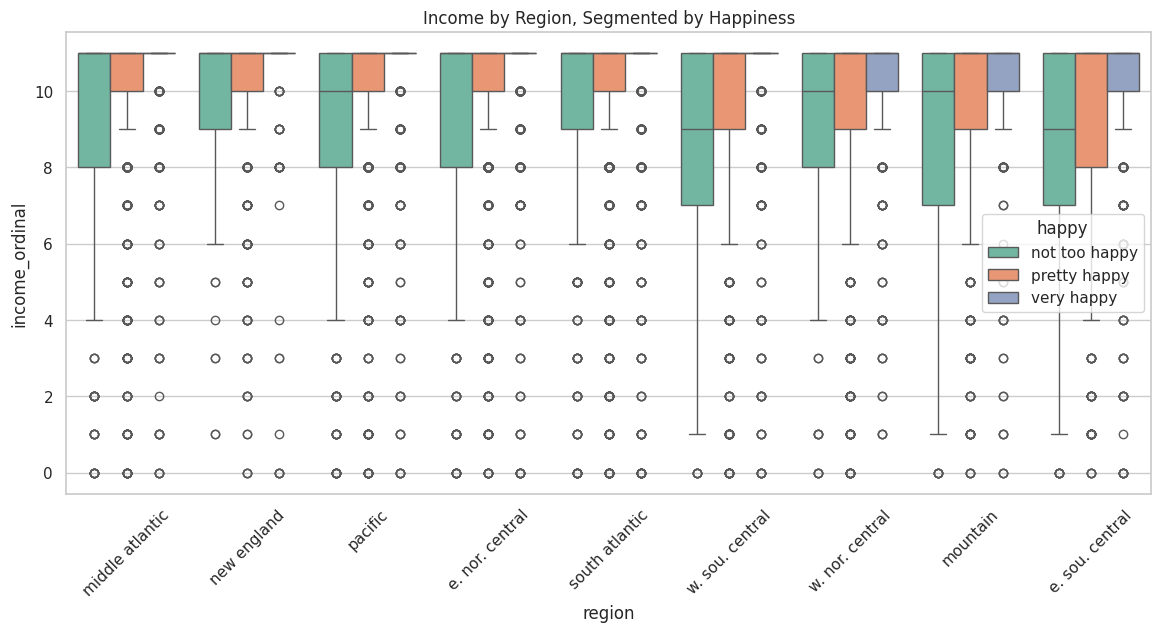

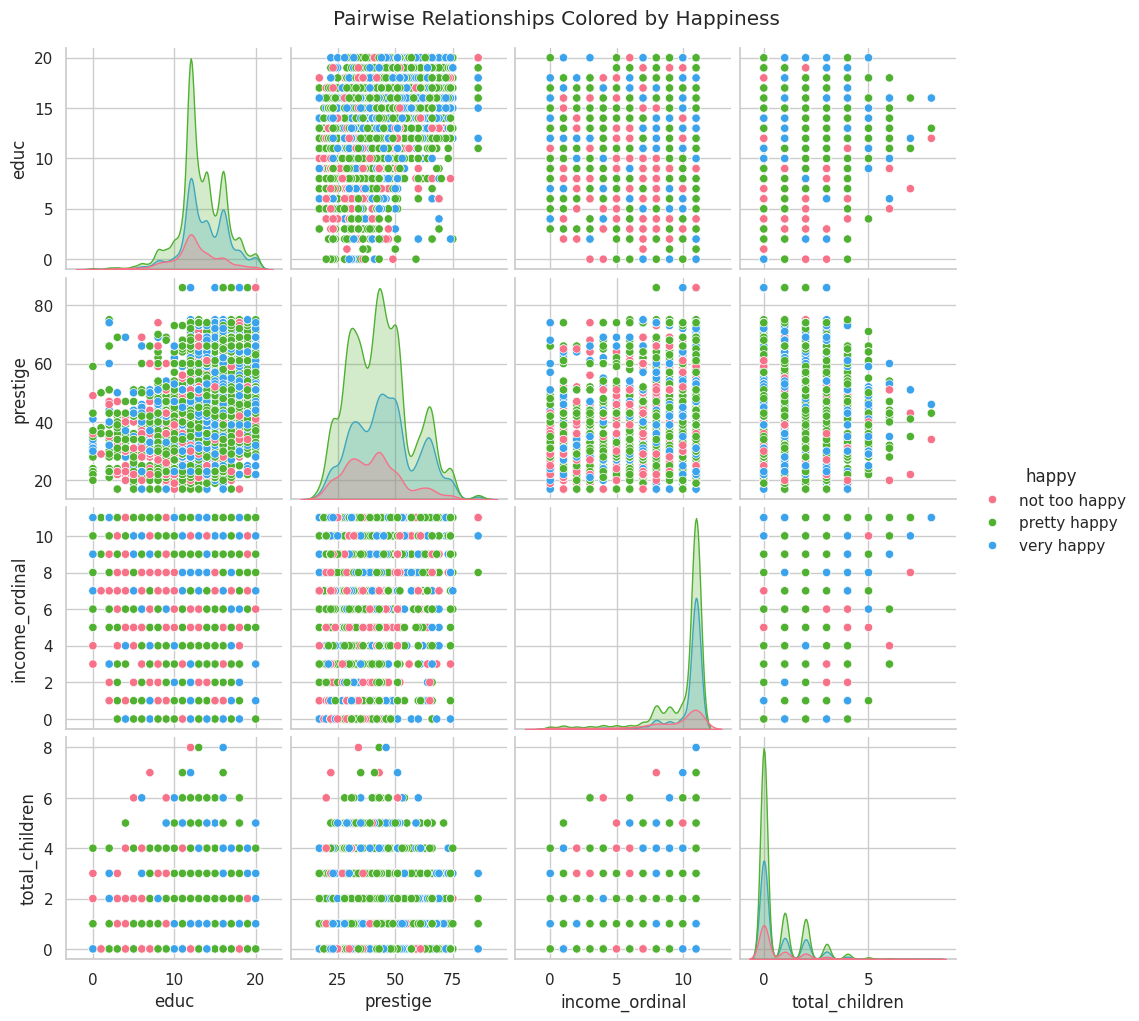

In [8]:
plt.figure(figsize=(10, 8))
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=False, cmap='coolwarm', center=0)
plt.title("Correlation Heatmap of Numeric Variables")
plt.show()

plt.figure(figsize=(14, 6))
sns.boxplot(x='region', y='income_ordinal', hue='happy', data=df, palette='Set2')
plt.title("Income by Region, Segmented by Happiness")
plt.xticks(rotation=45)
plt.show()

key_vars = ['educ', 'prestige', 'income_ordinal', 'total_children', 'happy']
sns.pairplot(df[key_vars], hue='happy', palette='husl', diag_kind='kde')
plt.suptitle("Pairwise Relationships Colored by Happiness", y=1.02)
plt.show()